# 04 · DBSCAN de hotspots (Sprint 5 · Paso 5 parte 2)

Kernel: **Python (chicago-crimes)**.

**Objetivo:** encontrar los hotspots *observados* — zonas donde el crimen
se acumula en densidad — con DBSCAN, explorar parámetros, visualizar y
**guardar la corrida en PostgreSQL** (proveniencia para el dashboard).

**Base:**
- El algoritmo vive en `src/models/dbscan.py` (testeado en
  `tests/unit/test_dbscan.py`): métrica **haversine** (eps en METROS
  reales), ruido label -1.
- Persistencia en `warehouse.hotspot_runs` + `warehouse.hotspot_clusters`
  (migración 005): append-only por corrida — re-correr con otros
  parámetros NO pisa los runs anteriores.


In [2]:
# Setup: imports, path de src (módulo models), conexión a dev (5432)
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg2

SRC_DIR = Path.cwd().resolve().parent / "src"
sys.path.insert(0, str(SRC_DIR))

from models import dbscan  # noqa: E402 — módulo testeado en tests/unit

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

DB = {"host": "localhost", "port": 5432, "user": "postgres",
      "password": "postgres", "dbname": "chicago_crimes"}
conn = psycopg2.connect(**DB)
# autocommit: cada SELECT es su propia transacción (evita la cascada
# InFailedSqlTransaction si una query falla); save_run maneja la SUYA.
conn.autocommit = True

def q(sql, params=None):
    """Query -> DataFrame (psycopg2 + pandas, sin SQLAlchemy)."""
    cur = conn.cursor()
    cur.execute(sql, params or ())
    cols = [d[0] for d in cur.description]
    out = pd.DataFrame(cur.fetchall(), columns=cols)
    cur.close()
    return out

print("PostgreSQL", conn.info.server_version)


PostgreSQL 160015


## 1 · Carga de puntos (staging, coordenadas válidas)


In [3]:
points = q("""
SELECT latitude, longitude
FROM staging.crimes
WHERE latitude IS NOT NULL AND longitude IS NOT NULL
""")
print(f"{len(points):,} puntos con coordenadas")


19,552 puntos con coordenadas


## 2 · Exploración de parámetros (eps × min_samples)

eps = radio del "vecindario" en metros reales; min_samples = mínimo de
puntos dentro del radio para ser núcleo denso. Reglas generales:

- eps pequeño → muchos micro-clusters (fragmentación)
- eps grande → una mega-bola que se traga la ciudad (inútil)
- min_samples alto → más ruido, clusters más "confiables"

Grid medido con estos datos: **200 m / 25** da 51 hotspots a escala de
cuadra (~1-2 manzanas) con centroide interpretable.


In [ ]:
rows = []
for eps_m in [150, 200, 300, 500]:
    for ms in [10, 25, 50]:
        lbls = dbscan.fit(points, eps_meters=eps_m, min_samples=ms)
        n_noise = lbls.count(-1)
        sizes = pd.Series(lbls).value_counts()
        sizes = sizes[sizes.index >= 0]
        rows.append({
            "eps_m": eps_m, "min_samples": ms,
            "clusters": len(sizes),
            "ruido_pct": round(100 * n_noise / len(lbls), 1),
            "mayor_cluster": int(sizes.max()) if len(sizes) else 0,
            "mediana_cluster": float(sizes.median()) if len(sizes) else 0.0,
        })
grid = pd.DataFrame(rows)
display(grid)


,eps_m,min_samples,clusters,ruido_pct,mayor_cluster,mediana_cluster
0,150,10,291,58.1,1317,16.0
1,150,25,26,91.3,371,41.0
2,150,50,6,97.3,161,74.5
3,200,10,271,36.9,1749,17.0
4,200,25,51,81.1,998,46.0
5,200,50,8,94.5,368,74.5
6,300,10,98,10.6,13469,16.0
7,300,25,89,44.8,2045,47.0
8,300,50,24,82.2,1375,72.0
9,500,10,19,1.4,18700,19.0


## 3 · Corrida elegida (parámetros arriba: ajusta y re-corre)


In [5]:
EPS_METERS = 200
MIN_SAMPLES = 25

labels = dbscan.fit(points, eps_meters=EPS_METERS, min_samples=MIN_SAMPLES)
n_noise = labels.count(-1)
print(f"clusters: {len({l for l in labels if l >= 0})} · "
      f"ruido: {n_noise:,} ({100 * n_noise / len(labels):.1f}%)")


clusters: 51 · ruido: 15,857 (81.1%)


## 4 · Visualización: nube coloreada por cluster (ruido en gris)


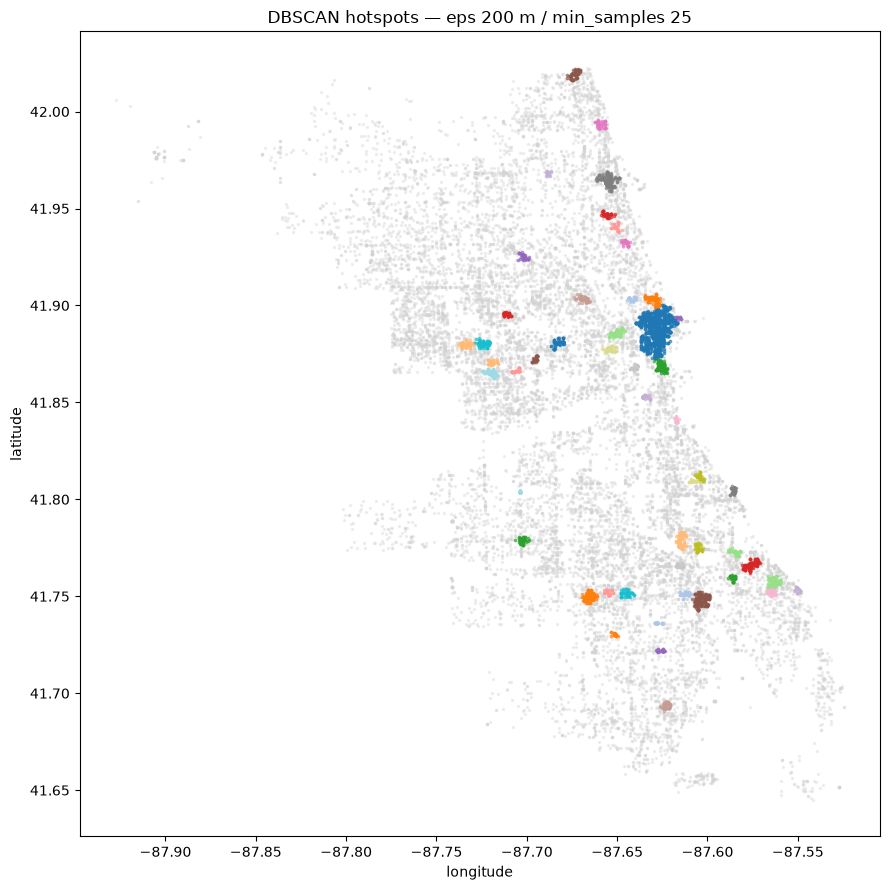

In [6]:
lbl = pd.Series(labels)
cmap = plt.get_cmap("tab20")

fig, ax = plt.subplots(figsize=(9, 9))
noise_mask = (lbl == -1).to_numpy()
# ruido primero (fondo gris), clusters encima (color)
ax.scatter(points.longitude[noise_mask], points.latitude[noise_mask],
           c="lightgray", s=2, alpha=0.3, label="ruido")
for c in sorted({l for l in labels if l >= 0}):
    m = (lbl == c).to_numpy()
    ax.scatter(points.longitude[m], points.latitude[m],
               color=cmap(c % 20), s=3, alpha=0.6)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title(f"DBSCAN hotspots — eps {EPS_METERS} m / min_samples {MIN_SAMPLES}")
plt.tight_layout()


## 5 · Resumen de clusters (lo que guardará la corrida)


,cluster_label,centroid_lat,centroid_lon,n_points,min_lat,max_lat,min_lon,max_lon
0,0,41.887979,-87.627714,998,41.872858,41.899990,-87.639615,-87.617043
1,14,41.964330,-87.655177,171,41.959087,41.969078,-87.661443,-87.648732
2,10,41.747902,-87.603374,149,41.743125,41.752403,-87.608795,-87.598607
3,3,41.778373,-87.614966,115,41.774224,41.783306,-87.617297,-87.611927
4,6,41.766073,-87.575884,109,41.762251,41.769330,-87.580965,-87.570991
5,2,41.903086,-87.630230,105,41.899127,41.906055,-87.634856,-87.626138
6,22,41.749874,-87.665491,99,41.746662,41.753155,-87.669519,-87.661009
7,4,41.868269,-87.625698,94,41.865131,41.871835,-87.629576,-87.622149
8,5,41.757390,-87.563537,94,41.754427,41.760671,-87.566399,-87.559223
9,20,41.880187,-87.634399,90,41.875177,41.884622,-87.637062,-87.632056


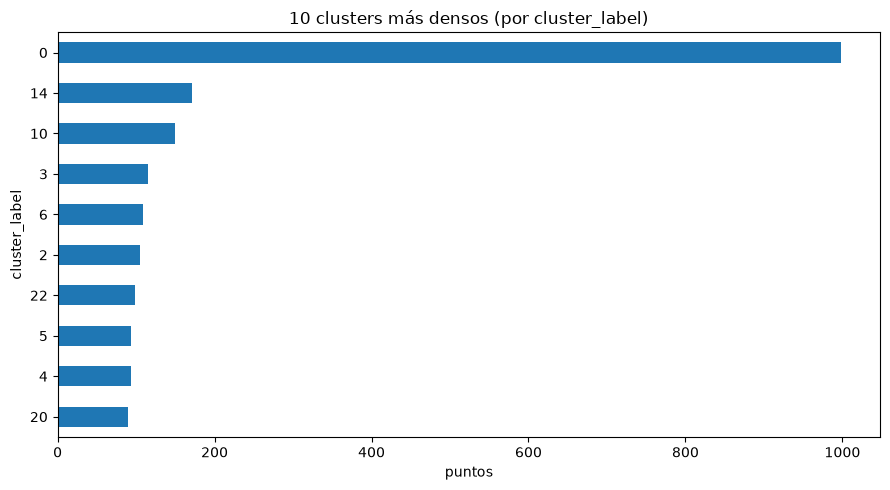

In [7]:
summary = dbscan.cluster_summaries(points, labels)
display(summary.head(10))

top10 = summary.head(10)
ax = top10.sort_values("n_points").plot.barh(
    x="cluster_label", y="n_points", figsize=(9, 5),
    title="10 clusters más densos (por cluster_label)", legend=False)
ax.set_xlabel("puntos"); ax.set_ylabel("cluster_label")
plt.tight_layout()


## 6 · Guardar la corrida en PostgreSQL (proveniencia)

Append-only: cada Run All crea una corrida NUEVA en
`warehouse.hotspot_runs` (y sus clusters en `hotspot_clusters`) — se puede
comparar entre corridas con `SELECT * FROM warehouse.hotspot_runs`.


In [8]:
run_key = dbscan.save_run(conn, eps_meters=EPS_METERS, min_samples=MIN_SAMPLES,
                          points=points, labels=labels)
print("run_key:", run_key)

q("SELECT * FROM warehouse.hotspot_runs ORDER BY run_key DESC LIMIT 3")


run_key: 1


,run_key,eps,min_samples,computed_at,n_clusters,n_noise
0,1,200.0,25,2026-10-20 06:19:05.654975+00:00,51,15857


In [9]:
q("""
SELECT hc.cluster_label, hc.n_points, hc.centroid_lat, hc.centroid_lon
FROM warehouse.hotspot_clusters hc
WHERE hc.run_key = %(run)s
ORDER BY hc.n_points DESC LIMIT 5
""", {"run": int(run_key)})


,cluster_label,n_points,centroid_lat,centroid_lon
0,0,998,41.887979,-87.627714
1,14,171,41.964330,-87.655177
2,10,149,41.747902,-87.603374
3,3,115,41.778373,-87.614966
4,6,109,41.766073,-87.575884


## 7 · Conclusiones (completar tras ver los outputs)

- ¿El grid confirma la sensibilidad esperada de DBSCAN (eps chico fragmenta,
  grande funde)?
- ¿Los clusters top coinciden con las áreas densas del notebook 03
  (Loop/Near North/Austin)?
- ¿El % de ruido es razonable para tu criterio operativo?
- ¿La corrida quedó guardada (run_key + filas en hotspot_clusters)?
